# Introduction

This notebook shows how to configure CNit, run a simple coupled carbon–nitrogen simulation, inspect its results, and plot carbon and nitrogen fluxes and pools. 

# Import required libraries and modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from cnit import CNitModel, CNitModelConfig, Q

# Set default plotting properties

In [2]:
plt.rcParams.update(
    {
        "font.size": 6,  # Default font size for all text
        "axes.titlesize": 6,  # Axes title
        "axes.labelsize": 6,  # Axes labels
        "xtick.labelsize": 6,  # X-axis tick labels
        "ytick.labelsize": 6,  # Y-axis tick labels
        "legend.fontsize": 6,  # Legend text
        "figure.titlesize": 6,  # Figure title
        "lines.linewidth": 0.5,  # Default line width
        "figure.figsize": (9 / 2.54, 6 / 2.54),  # Default figure size in cm
        "figure.dpi": 150,  # Default DPI for figures
        "figure.constrained_layout.use": True,  # Use constrained layout by default
        "xtick.major.size": 1,  # X-axis major tick length
        "ytick.major.size": 1,  # Y-axis major tick length
    }
)

# Create default model and define forcing

The short class names are aliases for the full carbon–nitrogen model classes. `Q` creates Pint quantities so that inputs carry units.

In [3]:
# Create model with default parameters
config = CNitModelConfig()
model = CNitModel.from_config(config)

In [4]:
# Set up time axis and forcing
time_axis = Q(np.arange(1850, 2101), "yr")
n_steps = len(time_axis)

dT_s = Q(np.linspace(0, 2, n_steps), "K")  # 2°C warming
CO2_s = Q(np.linspace(284.875, 284.875 * 2, n_steps), "ppm")  # CO2 doubling

# Land use carbon emissions (zero for simplicity)
CemsLUnet_s = Q(np.zeros(n_steps), "GtC/yr")
CemsLUgrs_s = Q(np.zeros(n_steps), "GtC/yr")

# Nitrogen inputs
NflxAD_s = Q(np.linspace(0, 0.15, n_steps), "GtN/yr")  # Increasing deposition
NflxFT_s = Q(np.linspace(0, 0.1, n_steps), "GtN/yr")  # Increasing fertilizer

# Land use nitrogen emissions (zero for simplicity)
NemsLUnet_s = Q(np.zeros(n_steps), "GtN/yr")
NemsLUgrs_s = Q(np.zeros(n_steps), "GtN/yr")
NemsLUmin_s = Q(np.zeros(n_steps), "GtN/yr")

# Initialise the model at equilibrium

Adjust the turnover times \tau\ so that the model starts from equilibrium under the initial forcing.

In [5]:
eqm0 = model.calculate_mdl_eqm0(
    dT_s,
    CO2_s,
    CemsLUnet_s,
    CemsLUgrs_s,
    NflxAD_s,
    NflxFT_s,
    NemsLUnet_s,
    NemsLUgrs_s,
    NemsLUmin_s,
)

for key, value in eqm0.items():
    if key.startswith("tau_") and key.endswith("_inverse"):
        attr = key.removesuffix("_inverse")
        if hasattr(config, attr):
            setattr(config, attr, value)

model = CNitModel.from_config(config)

# Run the simulation

Pass the time axis and all required forcing series to `model.run`. The result is an xarray Dataset containing carbon and nitrogen states and fluxes.

In [6]:
res = model.run(
    time_axis=time_axis,
    dT_s=dT_s,
    CO2_s=CO2_s,
    CemsLUnet_s=CemsLUnet_s,
    CemsLUgrs_s=CemsLUgrs_s,
    NflxAD_s=NflxAD_s,
    NflxFT_s=NflxFT_s,
    NemsLUnet_s=NemsLUnet_s,
    NemsLUgrs_s=NemsLUgrs_s,
    NemsLUmin_s=NemsLUmin_s,
)

# Inspect the results

Units are available in each variable's dataset attributes.

In [7]:
# Carbon fluxes
npp = res["CflxNPP"]
rh = res["CflxRH"]
nbp = res["CflxNetPLS"]

# Carbon pools
cVeg = res["CplsP"]
cLitter = res["CplsL"]
cSoil = res["CplsS"]
cLand = res["CplsPLS"]

# Nitrogen fluxes
bnf = res["NflxBNF"]
fNup = res["NflxPU"]
nLoss = res["NflxLS"]
nNetLand = res["NflxNetPLSM"]

# Nitrogen pools
nVeg = res["NplsP"]
nLitter = res["NplsL"]
nSoil = res["NplsS"]
nMineral = res["NplsM"]
nLand = res["NplsPLSM"]

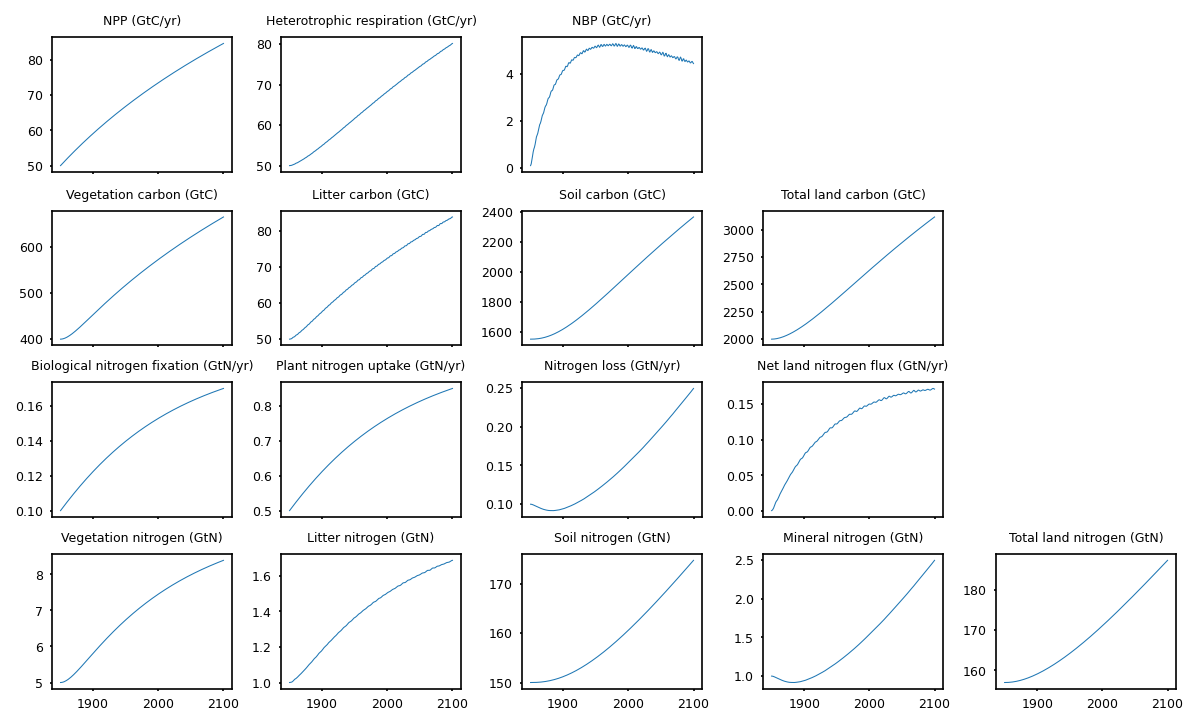

In [8]:
time = time_axis.m

groups = [
    [
        (npp, "NPP", "GtC/yr"),
        (rh, "Heterotrophic respiration", "GtC/yr"),
        (nbp, "NBP", "GtC/yr"),
    ],
    [
        (cVeg, "Vegetation carbon", "GtC"),
        (cLitter, "Litter carbon", "GtC"),
        (cSoil, "Soil carbon", "GtC"),
        (cLand, "Total land carbon", "GtC"),
    ],
    [
        (bnf, "Biological nitrogen fixation", "GtN/yr"),
        (fNup, "Plant nitrogen uptake", "GtN/yr"),
        (nLoss, "Nitrogen loss", "GtN/yr"),
        (nNetLand, "Net land nitrogen flux", "GtN/yr"),
    ],
    [
        (nVeg, "Vegetation nitrogen", "GtN"),
        (nLitter, "Litter nitrogen", "GtN"),
        (nSoil, "Soil nitrogen", "GtN"),
        (nMineral, "Mineral nitrogen", "GtN"),
        (nLand, "Total land nitrogen", "GtN"),
    ],
]

fig, axs = plt.subplots(4, 5, figsize=(20 / 2.54, 12 / 2.54), sharex=True)

for row, group in enumerate(groups):
    for col, (variable, label, unit) in enumerate(group):
        ax = axs[row, col]
        ax.plot(time, variable.values)
        ax.set_title(label + " (" + unit + ")")

    for col in range(len(group), 5):
        axs[row, col].set_visible(False)

plt.show()